# Лабораторная работа 3. 3D диод — ISE TCAD

Параллелепипед кремния, переход посередине по высоте, анод сверху, катод — вся
нижняя грань. Диоды A и B отличаются только анодом: у B он вдвое уже.

Этапы как в методических указаниях: геометрия → сетка и легирование → решение →
сечения → иллюстрации. Расчёт идёт в ISE внутри Windows XP, управление — по telnet
(`tools/xp.py`). Без виртуальной машины выполняются все ячейки, кроме помеченных
`RUN`: тогда используются уже выгруженные файлы из `ise/`.

In [1]:
import sys, os
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "tools")) and ROOT != "/":
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, "tools"))
LAB = os.path.join(ROOT, "Lab3_diode_3D")
sys.path.insert(0, LAB)
import numpy as np
from IPython.display import Image, display

import re, time

RUN = False                  # True — пересчитать в ISE, False — взять готовые файлы из ise/
WORK = r"C:\tcad\L3v4"       # папка внутри Windows
ISE = os.path.join(LAB, "ise")
os.chdir(ISE)
if RUN:
    import xp, put
print(os.getcwd())

/Users/phoenix/Documents/MIET/labs_modelling/Nanostructure_Modelling_Course_MIET_2026/Lab3_diode_3D/ise


In [2]:
# ---- ВАРИАНТ ----
VARIANT = 2
LX, LY, LZ = 1.0, 3.0, 0.8      # мкм: x × y × z, LZ — толщина d
NB  = 1.4e+17                   # бор, сверху, 1/см3
NAs = 1.0e+17                   # мышьяк, снизу, 1/см3
ANODE = {"A": (0, 1, 1, 2), "B": (0.5, 1, 1, 2)}   # (x0, y0, x1, y1), мкм
# -----------------
ZJ = LZ / 2                     # переход посередине по высоте

## 1. Структура

Файл `.bnd`: кремний и два контакта. Анод A — во всю ширину по x, анод B — правая половина.
Каждый файл сверяется с тем, что лежит в `ise/`.

In [3]:
def write(name, text, crlf=False):
    """Записать файл в ise/ и сообщить, совпал ли он с прежним."""
    old = open(name, newline="").read() if os.path.exists(name) else None
    new = text.replace("\n", "\r\n") if crlf else text
    with open(name, "w", newline="") as f:
        f.write(new)
    print("%-12s %s" % (name, "без изменений" if old == new else "ОБНОВЛЁН" if old else "создан"))

for t, (x0, y0, x1, y1) in ANODE.items():
    write("s%s.bnd" % t, f"""Silicon "SiW"
{{
\tcuboid [(0,0,0) ({LX:g},{LY:g},{LZ:g})]
}}

Contact "Anode"
{{
\trectangle [({x0:g},{y0:g},{LZ:g}) ({x1:g},{y1:g},{LZ:g})]
}}

Contact "Cathode"
{{
\trectangle [(0,0,0) ({LX:g},{LY:g},0)]
}}
""")

sA.bnd       без изменений
sB.bnd       без изменений


## 2. Сетка и легирование

Сетка подобрана под эталонную иллюстрацию варианта 2 (1820 узлов): шаги по Oz не
делятся на k, в отличие от работ 1–2. Окно `Mesh2` — у анода, на верхней пятой части
толщины. `MaxElementSize` — потолок: генератор делит ячейку пополам, пока она больше.
Подбор описан в [заметке об ISE](../notes/ise_in_practice.md#3d-в-ise-решатель-сетка-и-ложные-признаки-успеха).
Файлы сетки A и B одинаковы.

In [4]:
cmd = f"""Title "3D Sharp Diode"

Definitions
{{
    Refinement "Mesh1"
    {{
      MaxElementSize = (0.25, 0.25, 0.2)
      MinElementSize = (0.05, 0.05, 0.02)
      RefineFunction = MaxTransDiff(Variable = "DopingConcentration", Value = 1)
    }}
    Refinement "Mesh2"
    {{
      MaxElementSize = (0.2, 0.2, 0.1)
      MinElementSize = (0.02, 0.02, 0.01)
    }}
    Constant "BW"  {{ Species = "BoronActiveConcentration"   Value = {NB:.1e} }}
    Constant "AsW" {{ Species = "ArsenicActiveConcentration" Value = {NAs:.1e} }}
}}

Placements
{{
    Refinement "Mesh1" {{ Reference = "Mesh1" }}
    Refinement "Mesh2" {{ Reference = "Mesh2"
      RefineWindow = cuboid [(0,{1 - 0.3:g},{0.8 * LZ:g}) ({LX:g},{2 + 0.3:g},{LZ:g})] }}
    Constant "BW"  {{ Reference = "BW"
      EvaluateWindow {{ Element = cuboid [(0,0,{ZJ:g}) ({LX:g},{LY:g},{LZ:g})] DecayLength = 0 }} }}
    Constant "AsW" {{ Reference = "AsW"
      EvaluateWindow {{ Element = cuboid [(0,0,0) ({LX:g},{LY:g},{ZJ:g})] DecayLength = 0 }} }}
}}
"""
for t in ANODE:
    write("s%s.cmd" % t, cmd)

sA.cmd       без изменений
sB.cmd       без изменений


## 3. Решатель

Командный файл — как в примере из методических указаний (`Sh3/sh2_des.cmd`).
`method=slip` обязателен: решатель по умолчанию (`Blocked`) рассчитан на смешанный
режим и на этой задаче не выполняет ни одной итерации.

In [5]:
des = """File {
\tGrid = "s{T}_msh.grd"
\tDoping = "s{T}_msh.dat"
\tPlot = "s{T}_des.dat"
\tCurrent = "s{T}_des.plt"
\tOutput = "s{T}_des.log"
}

Electrode {
\t{ Name="Anode"   Voltage=0.0 }
\t{ Name="Cathode" Voltage=0.0 }
}

Physics {
\tMobility( DopingDep HighFieldsat Enormal )
\tEffectiveIntrinsicDensity(BandGapNarrowing (OldSlotboom))
}

Plot {
\teDensity hDensity eCurrent hCurrent
\tPotential SpaceCharge ElectricField
\teMobility hMobility eVelocity hVelocity
\tDoping DonorConcentration AcceptorConcentration
\tCurrent/Vector
\tTotalCurrent/Vector
\tElectricField/Vector
}

Math {
\tExtrapolate
\tDerivatives
\tRelErrControl
\tNewDiscretization

\titerations=5
\tmethod=slip
}

Solve {
\tPoisson
\tCoupled { Poisson Electron Hole}
\tQuasistationary ( MaxStep=0.05 Goal { Name="Anode" Voltage=4 } )
\t{ Coupled { Poisson Electron Hole} }
}
"""
for t in ANODE:
    write("s%s_des.cmd" % t, des.replace("{T}", t))

sA_des.cmd   без изменений
sB_des.cmd   без изменений


## 4. Сечения и командные файлы прогона

`dfisetools -cut` читает точку и нормаль плоскости: y = 1.5 — поперёк прибора,
x = 0.75 и x = 0.25 — вдоль. Линия `topline` — верхняя граница сечения y = 1.5 в
координатах среза (первая координата среза — это −x).

Прогон одного диода — `run<диод>.bat`: сетка, решатель, сечения. Код возврата `dessis`
ненадёжен, поэтому в `p<диод>.txt` пишутся отметки этапов, а результат проверяется
по числу точек в `.plt`.

In [6]:
CUTS = {"A": [("Ay", (0.5, 1.5, ZJ), (0, 1, 0))],
        "B": [("By", (0.5, 1.5, ZJ), (0, 1, 0)),
              ("Bx75", (0.75, 1.5, ZJ), (1, 0, 0)),
              ("Bx25", (0.25, 1.5, ZJ), (1, 0, 0))]}
for t, cuts in CUTS.items():
    for name, p, n in cuts:
        write("cut%s.txt" % name, "\n".join("%g" % v for v in p + n) + "\n")
write("topline.txt", "-%.1f\n%g\n0.0\n%g\n" % (LX, LZ, LZ))

def bat(t):
    L = ["@echo off", r"cd /d %s" % WORK, "echo START > p%s.txt" % t,
         r"C:\ISE\bin\mesh -t s%s > m%s.log 2>&1" % (t, t), "echo mesh %s >> p%s.txt" % (t, t),
         r"C:\ISE\bin\dessis s%s_des.cmd > s%s_run.log 2>&1" % (t, t), "echo solve %s >> p%s.txt" % (t, t)]
    for name, _, _ in CUTS[t]:
        L += ["if exist %s.grd del %s.grd" % (name, name), "if exist %s.dat del %s.dat" % (name, name),
              "if exist s%s_msh_cut.grd del s%s_msh_cut.grd" % (t, t), "if exist s%s_des_cut.dat del s%s_des_cut.dat" % (t, t),
              r"C:\ISE\bin\dfisetools -cut s%s_msh.grd s%s_des.dat < cut%s.txt > c_%s.log 2>&1" % (t, t, name, name),
              "ren s%s_msh_cut.grd %s.grd" % (t, name), "ren s%s_des_cut.dat %s.dat" % (t, name)]
    y = CUTS[t][0][0]
    L += ["if exist %sTop.plt del %sTop.plt" % (y, y), "if exist %s_plt.plt del %s_plt.plt" % (y, y),
          r"C:\ISE\bin\dfisetools -plot %s.grd %s.dat < topline.txt > p_%s.log 2>&1" % (y, y, y),
          "ren %s_plt.plt %sTop.plt" % (y, y), "echo ALL DONE >> p%s.txt" % t]
    return "\n".join(L) + "\n"

for t in ANODE:
    write("run%s.bat" % t, bat(t), crlf=True)

cutAy.txt    без изменений
cutBy.txt    без изменений
cutBx75.txt  без изменений
cutBx25.txt  без изменений
topline.txt  без изменений
runA.bat     без изменений
runB.bat     без изменений


## 5. Расчёт в ISE

Расчёт одного диода — около 10 минут, дольше, чем живёт сеанс telnet, поэтому
командный файл ставится в очередь `at` и опрашивается по `p<диод>.txt`. Перед
постановкой очередь очищается: старые задания перезапускают прогон поверх идущего.

In [7]:
FILES = ["sA.bnd", "sB.bnd", "sA.cmd", "sB.cmd", "sA_des.cmd", "sB_des.cmd", "topline.txt",
         "cutAy.txt", "cutBy.txt", "cutBx75.txt", "cutBx25.txt", "runA.bat", "runB.bat"]

def run_at(t, wait=60, limit=3600):
    """Поставить run<t>.bat в очередь at через 2 минуты и дождаться ALL DONE."""
    now = xp.run(["time /t"]).split("time /t")[-1]
    h, m = map(int, re.search(r"(\d{1,2}):(\d{2})", now).groups())
    m += 2; h = (h + m // 60) % 24; m %= 60
    print(xp.run(["at /delete /yes", r"at %02d:%02d cmd /c %s\run%s.bat" % (h, m, WORK, t), "at"])[-300:])
    t0 = time.time()
    while time.time() - t0 < limit:
        time.sleep(wait)
        if "ALL DONE" in xp.run([r"cd /d %s" % WORK, "type p%s.txt" % t]):
            break
    print("диод %s: %.0f мин" % (t, (time.time() - t0) / 60))

if RUN:
    cmds = [r"mkdir %s" % WORK]
    for f in FILES:
        cmds += put.commands_for(f, r"%s\%s" % (WORK, f))
    xp.run(cmds, total=2400)
    for t in ANODE:
        run_at(t)

## 6. Результаты

Из виртуальной машины забираются сетки, ВАХ, трёхмерные поля при 4 В и сечения.
Расчёт считается выполненным, только если ВАХ дошла до 4 В.

In [8]:
OUTS = {"A": ["sA_msh.grd", "sA_msh.dat", "sA_des.plt", "sA_des.dat", "Ay.grd", "Ay.dat", "AyTop.plt"],
        "B": ["sB_msh.grd", "sB_msh.dat", "sB_des.plt", "sB_des.dat", "By.grd", "By.dat",
              "Bx75.grd", "Bx75.dat", "Bx25.grd", "Bx25.dat", "ByTop.plt"]}
if RUN:
    for t, files in OUTS.items():
        for f in files:
            xp.fetch(r"%s\%s" % (WORK, f), f)

import dfise
import json, viz
ref = json.load(open(os.path.join(LAB, "devsim", "reference_iv.json")))

def ise_iv(t):
    d = viz.read_plt(os.path.join(LAB, "ise", "s%s_des.plt" % t))
    return np.asarray(d["Anode OuterVoltage"]), np.abs(np.asarray(d["Anode TotalCurrent"]))

def at(c, v):
    return float(np.interp(v, c[0], c[1]))
for t in ANODE:
    g = dfise.read_grid3d("s%s_msh.grd" % t)
    V, I = ise_iv(t)
    print("диод %s: %d узлов, %d точек ВАХ, до %.2f В, I(4 В) = %.3f мА"
          % (t, len(g["vertices"]), len(V), V.max(), I[np.argmax(V)] * 1e3))

диод A: 1820 узлов, 26 точек ВАХ, до 4.00 В, I(4 В) = 5.401 мА
диод B: 1820 узлов, 26 точек ВАХ, до 4.00 В, I(4 В) = 3.308 мА


### Сравнение ВАХ с эталоном

Эталон оцифрован с иллюстрации варианта 2 (`devsim/reference_iv.py`).

In [9]:
rA, rB = np.array(ref["A"]), np.array(ref["B"])
iA, iB = ise_iv("A"), ise_iv("B")
print("U, В   эталон A   ISE A          эталон B   ISE B")
for v in (1.0, 1.5, 2.0, 3.0, 3.95):
    a, b = at(iA, v), at(iB, v)
    print("%.2f   %.3f      %.3f %+5.1f%%   %.3f      %.3f %+5.1f%%"
          % (v, at(rA, v) * 1e3, a * 1e3, (a / at(rA, v) - 1) * 100,
             at(rB, v) * 1e3, b * 1e3, (b / at(rB, v) - 1) * 100))
print("B ниже A при 3.95 В: ISE %.1f%%, эталон %.1f%%"
      % ((1 - at(iB, 3.95) / at(iA, 3.95)) * 100, (1 - at(rB, 3.95) / at(rA, 3.95)) * 100))

U, В   эталон A   ISE A          эталон B   ISE B
1.00   0.826      0.890  +7.7%   0.592      0.636  +7.4%
1.50   3.009      3.093  +2.8%   2.029      2.111  +4.1%
2.00   4.143      4.211  +1.7%   2.679      2.735  +2.1%
3.00   5.033      5.102  +1.4%   3.111      3.161  +1.6%
3.95   5.300      5.391  +1.7%   3.250      3.303  +1.6%
B ниже A при 3.95 В: ISE 38.7%, эталон 38.7%


## 7. Иллюстрации

Все позиции строятся в ракурсе, размере и шкалах эталонных иллюстраций
(`make_figures.py`, `tools/ise3d.py`). Сечения — из трёхмерного поля по тетраэдрам
сетки: в срезах `dfisetools` вектор тока только в плоскости среза.

ISE: A 0.00540 А, B 0.00331 А при 4 В


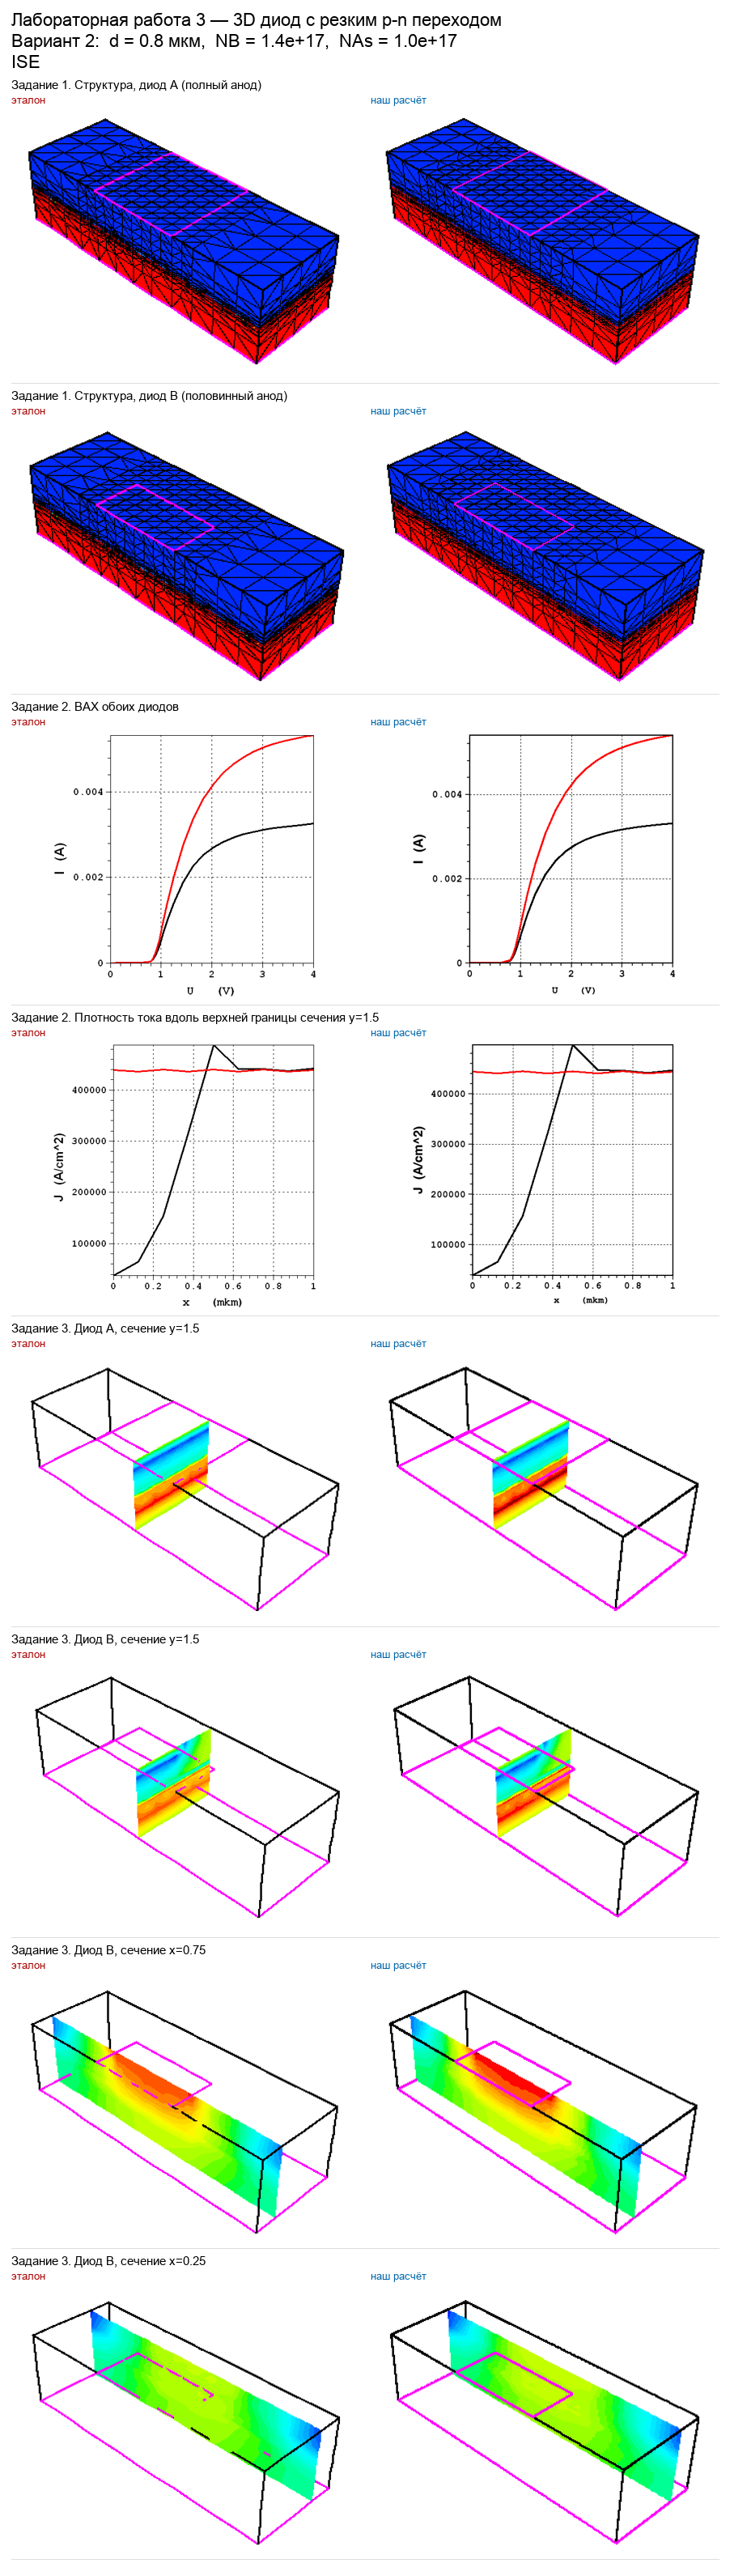

In [10]:
import make_figures as mf
mf.figures_ise()
mf.sheets()
display(Image(os.path.join(LAB, "results", "ise", "СВОДНЫЙ_ЛИСТ.png")))

### Вывод

_(ВАХ и контраст токов A и B, распределение тока под анодом, область пространственного заряда)_